In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import warnings
warnings.filterwarnings('ignore')

print("✅ Library berhasil diimport!")

✅ Library berhasil diimport!


In [12]:
# Load data
df = pd.read_excel('../dataset/laporan_iklim_harian_2024-2026.xlsx')

# Hapus kolom tidak perlu
df = df[['TANGGAL', 'TN', 'TX', 'TAVG', 'RH_AVG', 'RR', 'SS', 'FF_AVG']]

# Ganti nilai 8888 dan 9999 dengan NaN
df.replace([8888, 9999, 8888.0, 9999.0], np.nan, inplace=True)

# Hapus baris yang ada NaN
df.dropna(inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

print(f"✅ Data bersih: {df.shape[0]} baris")
print(df.head())

✅ Data bersih: 636 baris
      TANGGAL    TN    TX  TAVG  RH_AVG    RR   SS  FF_AVG
0  04-03-2024  24.0  29.9  27.0    91.0  41.3  2.0     1.0
1  05-03-2024  24.2  33.1  26.6    91.0   1.1  0.3     2.0
2  06-03-2024  24.3  35.0  28.8    80.0   0.0  1.9     1.0
3  07-03-2024  24.2  32.7  26.9    91.0   5.7  5.0     2.0
4  08-03-2024  24.3  30.4  26.7    92.0  15.5  3.7     1.0


In [13]:
# Fungsi labeling cuaca berdasarkan RR (curah hujan) dan SS (sinar matahari)
def label_cuaca(row):
    rr = row['RR']
    ss = row['SS']
    
    if rr > 20:
        return 'Hujan Lebat'
    elif rr > 0:
        return 'Hujan Ringan'
    elif ss >= 6:
        return 'Cerah'
    else:
        return 'Berawan'

df['CUACA'] = df.apply(label_cuaca, axis=1)

print("✅ Label cuaca berhasil dibuat!")
print(df['CUACA'].value_counts())

✅ Label cuaca berhasil dibuat!
CUACA
Hujan Ringan    277
Berawan         157
Cerah           104
Hujan Lebat      98
Name: count, dtype: int64


In [14]:
# Fitur (X) dan Label (y)
X = df[['TN', 'TX', 'TAVG', 'RH_AVG', 'RR', 'SS', 'FF_AVG']]
y = df['CUACA']

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Training model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("✅ Model berhasil dilatih!")
print(f"Jumlah data training : {len(X_train)}")
print(f"Jumlah data testing  : {len(X_test)}")

✅ Model berhasil dilatih!
Jumlah data training : 508
Jumlah data testing  : 128


In [15]:
# Prediksi
y_pred = model.predict(X_test)

# Akurasi
akurasi = accuracy_score(y_test, y_pred)
print(f"🎯 Akurasi Model: {akurasi * 100:.2f}%")
print()
print("📊 Laporan Klasifikasi:")
print(classification_report(y_test, y_pred))

🎯 Akurasi Model: 100.00%

📊 Laporan Klasifikasi:
              precision    recall  f1-score   support

     Berawan       1.00      1.00      1.00        34
       Cerah       1.00      1.00      1.00        15
 Hujan Lebat       1.00      1.00      1.00        22
Hujan Ringan       1.00      1.00      1.00        57

    accuracy                           1.00       128
   macro avg       1.00      1.00      1.00       128
weighted avg       1.00      1.00      1.00       128



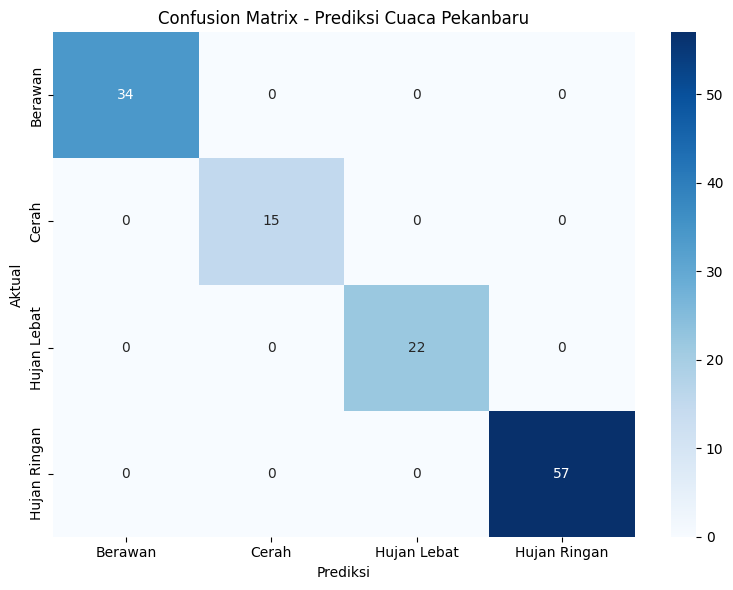

✅ Grafik tersimpan!


In [16]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_,
            yticklabels=model.classes_)
plt.title('Confusion Matrix - Prediksi Cuaca Pekanbaru')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.savefig('../img/confusion_matrix.png')
plt.show()
print("✅ Grafik tersimpan!")

In [17]:
import joblib
joblib.dump(model, '../model/model_random_forest.pkl')
print("✅ Model tersimpan di folder model/")

✅ Model tersimpan di folder model/
